In [1]:
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import (roc_curve, precision_recall_curve, roc_auc_score,
                             average_precision_score, brier_score_loss, confusion_matrix)

DATA = "s3://sagemaker-salesmesh-myra/processed/"
train = pd.read_csv(DATA + "train.csv")
test = pd.read_csv(DATA + "test.csv")
LABEL = "fraud_bool"
y_train, y_test = train[LABEL], test[LABEL]

lr = joblib.load("../artifacts/lr_core.joblib")
rf = joblib.load("../artifacts/rf_core.joblib")

CAT = ["source", "device_os"]
FEATS = lr["features"]                                             # 14 features
NOAGE = [f for f in FEATS if f != "customer_age"]                  # 13 features
SAFE = [f for f in FEATS if f not in ("customer_age", "phone_home_valid", "device_os")]  # 11
OLD = test["customer_age"] >= 50                                   # used only to MEASURE fairness

def build_lr(features, C=0.01):
    num = [c for c in features if c not in CAT]
    cat = [c for c in features if c in CAT]
    prep = ColumnTransformer([
        ("num", Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True)),
                          ("scale", StandardScaler())]), num),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat),
    ])
    return Pipeline([("prep", prep),
                     ("model", LogisticRegression(class_weight="balanced", max_iter=2000, C=C))])

def recall_at_fpr(y_true, y_prob, max_fpr=0.05):
    fpr, tpr, thr = roc_curve(y_true, y_prob)
    i = np.searchsorted(fpr, max_fpr, side="right") - 1
    return tpr[i], thr[i]

def evaluate(name, model, feats):
    p = model.predict_proba(test[feats])[:, 1]
    rec, thr = recall_at_fpr(y_test, p)
    pred = p >= thr
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    fpr_young = pred[~OLD & (y_test == 0)].mean()
    fpr_old = pred[OLD & (y_test == 0)].mean()
    return {"model": name, "n_features": len(feats),
            "recall@5%FPR": round(rec, 4), "threshold": round(thr, 4),
            "precision": round(tp / (tp + fp), 4), "FPR": round(fp / (fp + tn), 4),
            "accuracy": round((tp + tn) / len(y_test), 4),
            "balanced_acc": round((tp / (tp + fn) + tn / (tn + fp)) / 2, 4),
            "ROC-AUC": round(roc_auc_score(y_test, p), 4),
            "PR-AUC": round(average_precision_score(y_test, p), 4),
            "Brier": round(brier_score_loss(y_test, p), 4),
            "mean_prob": round(p.mean(), 4),
            "FPR <50": round(fpr_young, 4), "FPR >=50": round(fpr_old, 4),
            "FPR ratio": round(min(fpr_young, fpr_old) / max(fpr_young, fpr_old), 3),
            "TP": tp, "FP": fp, "FN": fn, "TN": tn}

print(train.shape, test.shape)
print(len(FEATS), len(NOAGE), len(SAFE), "features")

(794989, 19) (205011, 19)
14 13 11 features


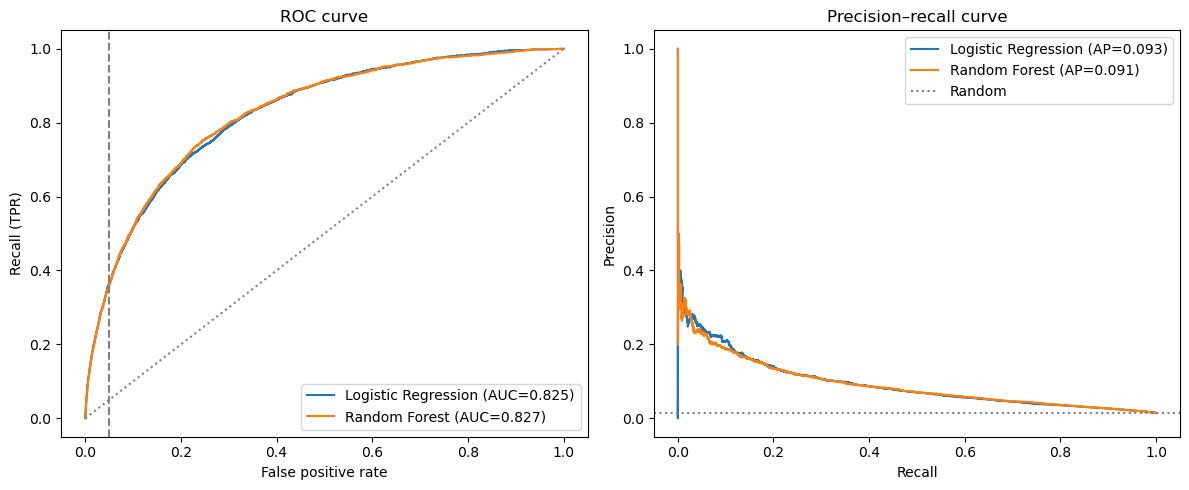

In [2]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for name, m in [("Logistic Regression", lr["model"]), ("Random Forest", rf["model"])]:
    p = m.predict_proba(test[FEATS])[:, 1]
    fpr, tpr, _ = roc_curve(y_test, p)
    prec, rec, _ = precision_recall_curve(y_test, p)
    ax[0].plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, p):.3f})")
    ax[1].plot(rec, prec, label=f"{name} (AP={average_precision_score(y_test, p):.3f})")
ax[0].axvline(0.05, ls="--", c="grey"); ax[0].plot([0, 1], [0, 1], ":", c="grey")
ax[0].set(xlabel="False positive rate", ylabel="Recall (TPR)", title="ROC curve")
ax[1].axhline(y_test.mean(), ls=":", c="grey", label="Random")
ax[1].set(xlabel="Recall", ylabel="Precision", title="Precision–recall curve")
ax[0].legend(); ax[1].legend(); plt.tight_layout()
plt.savefig("../artifacts/curves.png", dpi=150); plt.show()

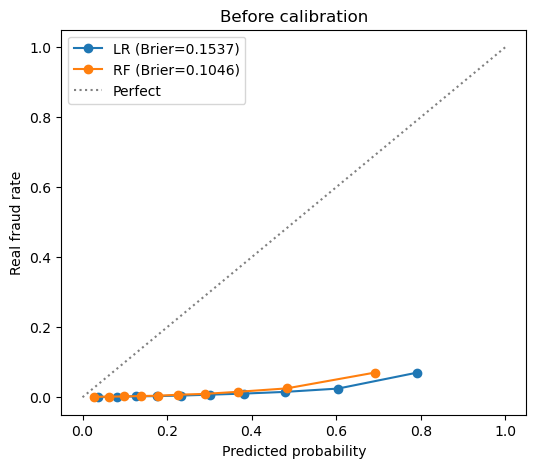

In [3]:
fig, ax = plt.subplots(figsize=(6, 5))
for name, m in [("LR", lr["model"]), ("RF", rf["model"])]:
    p = m.predict_proba(test[FEATS])[:, 1]
    frac, mean = calibration_curve(y_test, p, n_bins=10, strategy="quantile")
    ax.plot(mean, frac, "o-", label=f"{name} (Brier={brier_score_loss(y_test, p):.4f})")
ax.plot([0, 1], [0, 1], ":", c="grey", label="Perfect")
ax.set(xlabel="Predicted probability", ylabel="Real fraud rate", title="Before calibration")
ax.legend(); plt.savefig("../artifacts/calibration_before.png", dpi=150); plt.show()

In [4]:
import time
candidates = {
    "LR with age":      (CalibratedClassifierCV(build_lr(FEATS), method="sigmoid", cv=3, ensemble=False), FEATS),
    "RF with age":      (CalibratedClassifierCV(rf["model"], method="isotonic", cv=3, ensemble=False), FEATS),
    "LR without age":   (CalibratedClassifierCV(build_lr(NOAGE), method="sigmoid", cv=3, ensemble=False), NOAGE),
    "LR transfer-safe": (CalibratedClassifierCV(build_lr(SAFE), method="sigmoid", cv=3, ensemble=False), SAFE),
}
for name, (model, feats) in candidates.items():
    t = time.time()
    model.fit(train[feats], y_train)
    print(f"{name:17} fitted in {(time.time() - t) / 60:.1f} min")

LR with age       fitted in 0.2 min
RF with age       fitted in 1.9 min
LR without age    fitted in 0.2 min
LR transfer-safe  fitted in 0.1 min


In [5]:
comparison = pd.DataFrame([evaluate(n, m, f) for n, (m, f) in candidates.items()]).set_index("model")
comparison.T

model,LR with age,RF with age,LR without age,LR transfer-safe
n_features,14.0000,14.0000,13.0000,11.0000
recall@5%FPR,0.3641,0.3513,0.3436,0.2196
threshold,0.0327,0.0432,0.0350,0.0300
precision,0.0942,0.0945,0.0894,0.0590
FPR,0.0498,0.0479,0.0498,0.0498
accuracy,0.9419,0.9437,0.9417,0.9399
balanced_acc,0.6572,0.6517,0.6469,0.5849
ROC-AUC,0.8250,0.8263,0.8165,0.7450
PR-AUC,0.0925,0.0875,0.0826,0.0459
Brier,0.0133,0.0133,0.0134,0.0137


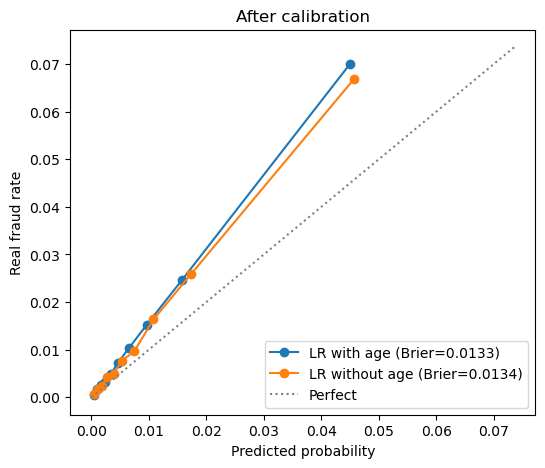

In [6]:
fig, ax = plt.subplots(figsize=(6, 5))
for name in ["LR with age", "LR without age"]:
    model, feats = candidates[name]
    p = model.predict_proba(test[feats])[:, 1]
    frac, mean = calibration_curve(y_test, p, n_bins=10, strategy="quantile")
    ax.plot(mean, frac, "o-", label=f"{name} (Brier={brier_score_loss(y_test, p):.4f})")
lim = max(ax.get_xlim()[1], ax.get_ylim()[1])
ax.plot([0, lim], [0, lim], ":", c="grey", label="Perfect")
ax.set(xlabel="Predicted probability", ylabel="Real fraud rate", title="After calibration")
ax.legend(); plt.savefig("../artifacts/calibration_after.png", dpi=150); plt.show()

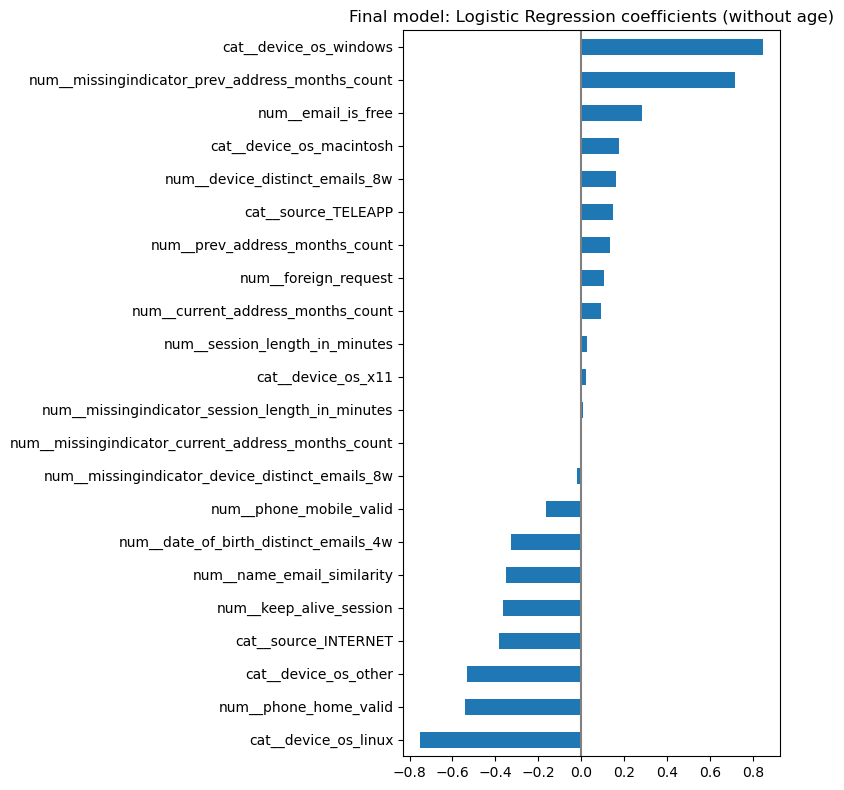

cat__device_os_linux                                 -0.749541
num__phone_home_valid                                -0.540325
cat__device_os_other                                 -0.531251
cat__source_INTERNET                                 -0.383711
num__keep_alive_session                              -0.362570
num__name_email_similarity                           -0.349974
num__date_of_birth_distinct_emails_4w                -0.327906
num__phone_mobile_valid                              -0.162233
num__missingindicator_device_distinct_emails_8w      -0.017381
num__missingindicator_current_address_months_count   -0.005383
num__missingindicator_session_length_in_minutes       0.010073
cat__device_os_x11                                    0.020162
num__session_length_in_minutes                        0.028881
num__current_address_months_count                     0.093655
num__foreign_request                                  0.106300
num__prev_address_months_count                        0

In [7]:
final_model, final_feats = candidates["LR without age"]
base = final_model.calibrated_classifiers_[0].estimator
names = base.named_steps["prep"].get_feature_names_out()
coef = pd.Series(base.named_steps["model"].coef_[0], index=names).sort_values()

coef.plot.barh(figsize=(8, 8), title="Final model: Logistic Regression coefficients (without age)")
plt.axvline(0, c="grey"); plt.tight_layout()
plt.savefig("../artifacts/final_coefficients.png", dpi=150); plt.show()
coef

In [8]:
final_row = comparison.loc["LR without age"]
joblib.dump({"model": final_model,
             "features": final_feats,
             "threshold": float(final_row["threshold"]),
             "metrics": final_row.to_dict()},
            "../artifacts/final_model.joblib")
comparison.to_csv("../artifacts/model_comparison.csv")
coef.to_csv("../artifacts/final_coefficients.csv")
print("Saved. Final threshold:", final_row["threshold"])

Saved. Final threshold: 0.035
